DSCI 552 Homework 6
Om Bhatt

1. Tree based methods
a

In [1]:
import warnings
warnings.filterwarnings("ignore")
import time
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, GridSearchCV, cross_val_score
from sklearn.metrics import confusion_matrix, roc_auc_score, roc_curve, accuracy_score, ConfusionMatrixDisplay
from xgboost import XGBClassifier
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.ensemble import BalancedRandomForestClassifier
from sklearn.preprocessing import StandardScaler

In [2]:
SEED = 552 #keeping the seed same for everything
pd.set_option("display.max_columns", 30)

In [3]:
#the csv file has some licence text at the top so we have to find the line where header "class" begins and skip all lines befor it
def read_aps(path):
    with open(path, encoding="latin-1") as f:
        for i, line in enumerate(f):
            if line.startswith("class"):
                break
    return pd.read_csv(path, skiprows=i, na_values="na")   # missing values are wrriten as "na" in this datset

#linking the dataset
train=read_aps(r"F:\USC_EE\Sem_3\DSCI_552\Hw6\aps_failure_training_set.csv")
test=read_aps(r"F:\USC_EE\Sem_3\DSCI_552\Hw6\aps_failure_test_set.csv")

In [4]:
print(train.shape, test.shape) # number of rows and columns capability for train and test
train.head() #first 5 rows

(60000, 171) (16000, 171)


,class,aa_000,ab_000,ac_000,ad_000,ae_000,af_000,ag_000,ag_001,ag_002,ag_003,ag_004,ag_005,ag_006,ag_007,...,eb_000,ec_00,ed_000,ee_000,ee_001,ee_002,ee_003,ee_004,ee_005,ee_006,ee_007,ee_008,ee_009,ef_000,eg_000
0,neg,76698,NaN,2.130706e+09,280.0,0.0,0.0,0.0,0.0,0.0,0.0,37250.0,1432864.0,3664156.0,1007684.0,...,2801180.0,2445.80,2712.0,965866.0,1706908.0,1240520.0,493384.0,721044.0,469792.0,339156.0,157956.0,73224.0,0.0,0.0,0.0
1,neg,33058,NaN,0.000000e+00,NaN,0.0,0.0,0.0,0.0,0.0,0.0,18254.0,653294.0,1720800.0,516724.0,...,3477820.0,2211.76,2334.0,664504.0,824154.0,421400.0,178064.0,293306.0,245416.0,133654.0,81140.0,97576.0,1500.0,0.0,0.0
2,neg,41040,NaN,2.280000e+02,100.0,0.0,0.0,0.0,0.0,0.0,0.0,1648.0,370592.0,1883374.0,292936.0,...,1040120.0,1018.64,1020.0,262032.0,453378.0,277378.0,159812.0,423992.0,409564.0,320746.0,158022.0,95128.0,514.0,0.0,0.0
3,neg,12,0.0,7.000000e+01,66.0,0.0,10.0,0.0,0.0,0.0,318.0,2212.0,3232.0,1872.0,0.0,...,0.0,1.08,54.0,5670.0,1566.0,240.0,46.0,58.0,44.0,10.0,0.0,0.0,0.0,4.0,32.0
4,neg,60874,NaN,1.368000e+03,458.0,0.0,0.0,0.0,0.0,0.0,0.0,43752.0,1966618.0,1800340.0,131646.0,...,21173050.0,1116.06,1176.0,404740.0,904230.0,622012.0,229790.0,405298.0,347188.0,286954.0,311560.0,433954.0,1218.0,0.0,0.0


In [5]:
#splitting data here into inputs and target. INputs = X , target =(y) pos = 1 neg = 0
X_train_raw= train.drop(columns=["class"])
X_test_raw = test.drop(columns=["class"])
y_train= (train["class"]=="pos").astype(int).values
y_test =(test["class"]=="pos").astype(int).values
features= X_train_raw.columns
print("number of features:", len(features))
#cheking if every column is numeric or not 
print(X_train_raw.dtypes.value_counts())

number of features: 170
float64    169
int64        1
Name: count, dtype: int64


In [6]:
#info and describe
X_train_raw.info()

X_train_raw.describe()

<class 'pandas.DataFrame'>
RangeIndex: 60000 entries, 0 to 59999
Columns: 170 entries, aa_000 to eg_000
dtypes: float64(169), int64(1)
memory usage: 77.8 MB


,aa_000,ab_000,ac_000,ad_000,ae_000,af_000,ag_000,ag_001,ag_002,ag_003,ag_004,ag_005,ag_006,ag_007,ag_008,...,eb_000,ec_00,ed_000,ee_000,ee_001,ee_002,ee_003,ee_004,ee_005,ee_006,ee_007,ee_008,ee_009,ef_000,eg_000
count,6.000000e+04,13671.000000,5.666500e+04,4.513900e+04,57500.000000,57500.000000,5.932900e+04,5.932900e+04,5.932900e+04,5.932900e+04,5.932900e+04,5.932900e+04,5.932900e+04,5.932900e+04,5.932900e+04,...,5.599300e+04,49761.000000,50447.000000,5.932900e+04,5.932900e+04,5.932900e+04,5.932900e+04,5.932900e+04,5.932900e+04,5.932900e+04,5.932900e+04,5.932900e+04,5.932900e+04,57276.000000,57277.000000
mean,5.933650e+04,0.713189,3.560143e+08,1.906206e+05,6.819130,11.006817,2.216364e+02,9.757223e+02,8.606015e+03,8.859128e+04,4.370966e+05,1.108374e+06,1.657818e+06,4.993098e+05,3.556989e+04,...,9.717093e+06,1353.131452,1452.155212,7.334042e+05,7.838746e+05,4.454897e+05,2.111264e+05,4.457343e+05,3.939462e+05,3.330582e+05,3.462714e+05,1.387300e+05,8.388915e+03,0.090579,0.212756
std,1.454301e+05,3.478962,7.948749e+08,4.040441e+07,161.543373,209.792592,2.047846e+04,3.420053e+04,1.503220e+05,7.617312e+05,2.374282e+06,3.262607e+06,3.909384e+06,1.422765e+06,2.201524e+05,...,4.274675e+07,3536.637285,3525.028652,2.416166e+06,2.570111e+06,1.155540e+06,5.433188e+05,1.168314e+06,1.121044e+06,1.069160e+06,1.728056e+06,4.495100e+05,4.747043e+04,4.368855,8.830641
min,0.000000e+00,0.000000,0.000000e+00,0.000000e+00,0.000000,0.000000,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,...,0.000000e+00,0.000000,0.000000,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000,0.000000
25%,8.340000e+02,0.000000,1.600000e+01,2.400000e+01,0.000000,0.000000,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,3.080000e+02,1.383400e+04,1.060800e+04,0.000000e+00,0.000000e+00,...,0.000000e+00,114.760000,98.000000,1.569800e+04,8.536000e+03,2.936000e+03,1.166000e+03,2.700000e+03,3.584000e+03,5.120000e+02,1.100000e+02,0.000000e+00,0.000000e+00,0.000000,0.000000
50%,3.077600e+04,0.000000,1.520000e+02,1.260000e+02,0.000000,0.000000,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,3.672000e+03,1.760200e+05,9.303360e+05,1.192040e+05,1.786000e+03,...,6.221100e+05,754.400000,832.000000,2.607040e+05,3.469400e+05,2.337960e+05,1.120860e+05,2.215180e+05,1.899880e+05,9.243200e+04,4.109800e+04,3.812000e+03,0.000000e+00,0.000000,0.000000
75%,4.866800e+04,0.000000,9.640000e+02,4.300000e+02,0.000000,0.000000,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,4.952200e+04,9.139640e+05,1.886608e+06,5.888200e+05,2.669000e+04,...,4.000270e+06,1379.380000,1504.000000,5.730600e+05,6.673900e+05,4.383960e+05,2.182320e+05,4.666140e+05,4.032220e+05,2.750940e+05,1.678140e+05,1.397240e+05,2.028000e+03,0.000000,0.000000
max,2.746564e+06,204.000000,2.130707e+09,8.584298e+09,21050.000000,20070.000000,3.376892e+06,4.109372e+06,1.055286e+07,6.340207e+07,2.288306e+08,1.791880e+08,9.402067e+07,6.334675e+07,1.770252e+07,...,1.322457e+09,106020.220000,82806.000000,7.498445e+07,9.822438e+07,7.793393e+07,3.775839e+07,9.715238e+07,5.743524e+07,3.160781e+07,1.195801e+08,1.926740e+07,3.810078e+06,482.000000,1146.000000


b i

In [7]:
#checking how much data is acutally missing
print("rows with atleast one missing value:", X_train_raw.isna().any(axis=1).mean())
print("fraction of missing cells overall:", X_train_raw.isna().values.mean())
#top 10 coloumns with the most missing values
nafraction = X_train_raw.isna().mean().sort_values(ascending=False)
print(nafraction.head(10).round(3))

rows with atleast one missing value: 0.99015
fraction of missing cells overall: 0.08333480392156863
br_000    0.821
bq_000    0.812
bp_000    0.796
bo_000    0.772
ab_000    0.772
cr_000    0.772
bn_000    0.733
bm_000    0.659
bl_000    0.455
bk_000    0.384
dtype: float64


In [8]:
#Nowe filling the missing values with median of each column , train gets train median and test gets test median as the footnote said
X_train = X_train_raw.fillna(X_train_raw.median())
X_test = X_test_raw.fillna(X_test_raw.median())
print("missing left:", X_train.isna().sum().sum(), X_test.isna().sum().sum())

missing left: 0 0


b ii

In [9]:
#coeffecient of variation = s/m for every feature
m= X_train.mean()
s= X_train.std(ddof=1)
cvtable= pd.DataFrame({"mean": m, "std": s, "CV": s/m})
cvtable= cvtable.sort_values("CV", ascending=False)
#if a column is constant its std is 0 so it gives no infromation 
print("constant features:", list(cvtable.index[cvtable["std"]==0]))
pd.set_option("display.max_rows", 200)  # so that all 170 rows are visble
cvtable

constant features: ['cd_000']


,mean,std,CV
cf_000,1.431075e+05,3.504525e+07,244.887517
co_000,1.433300e+05,3.504525e+07,244.507385
ad_000,1.434383e+05,3.504525e+07,244.322816
cs_009,7.705097e+02,1.833278e+05,237.930554
dh_000,4.392641e+03,5.412441e+05,123.216097
dj_000,3.727133e+01,4.379166e+03,117.494225
ag_000,2.191577e+02,2.036364e+04,92.917755
as_000,1.254079e+02,1.095219e+04,87.332500
ay_009,1.149620e+03,9.741156e+04,84.733735
ak_000,9.076607e+02,7.299859e+04,80.424975


b iii

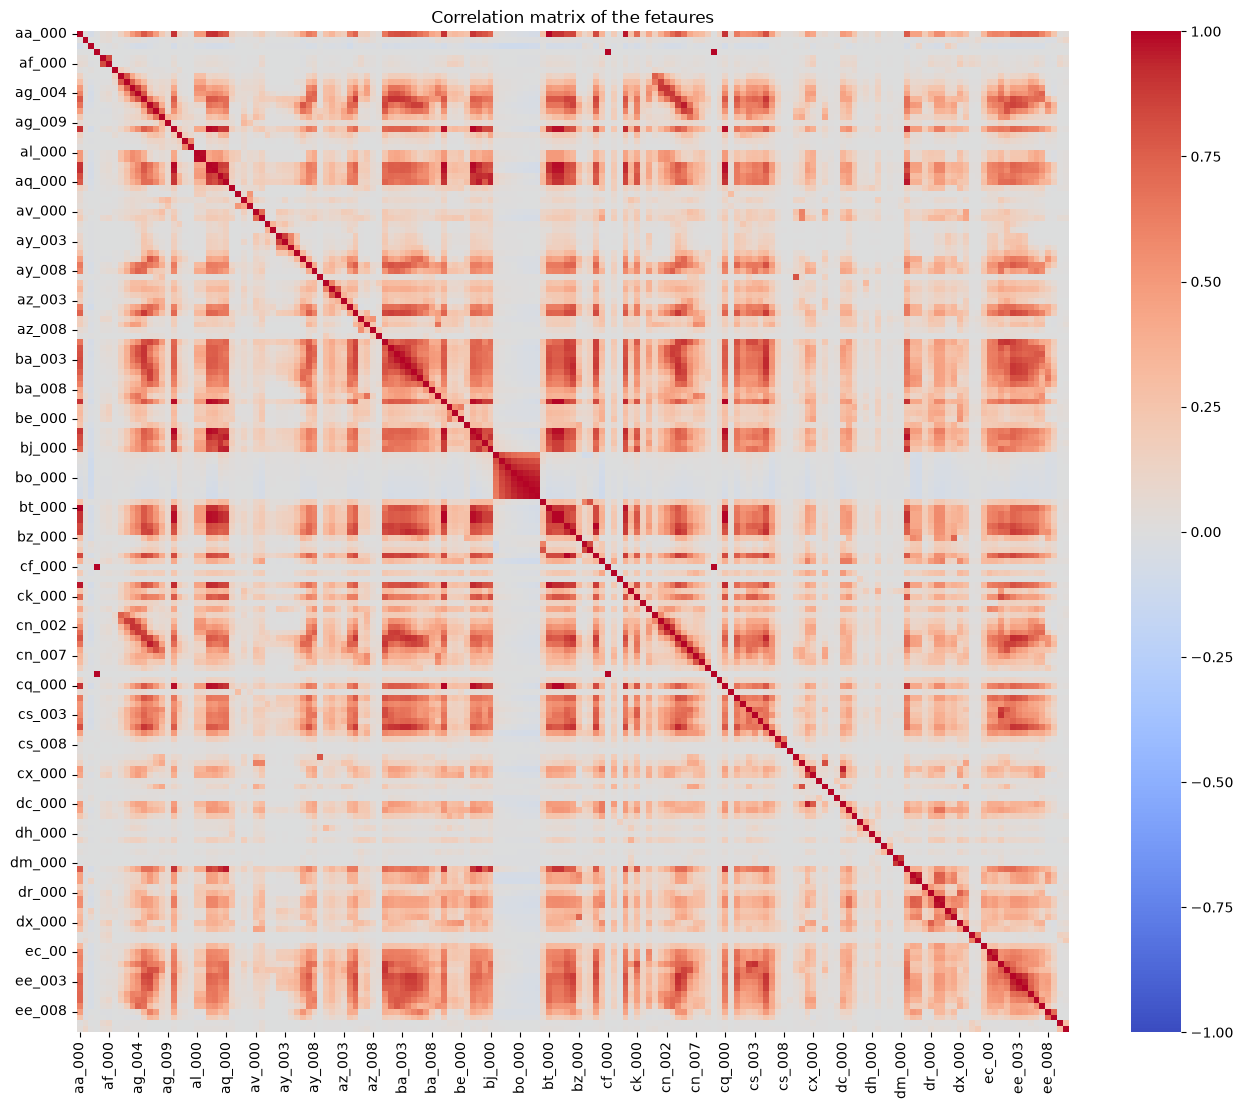

pairs with |r| > 0.9 : 130 out of 14196


In [10]:
#correlation matrix , removing the constant columns first becuase thier correlation comes out NaN
Xnonconst = X_train.loc[:, X_train.std() > 0]
corr = Xnonconst.corr()
plt.figure(figsize=(16, 13))     #
sns.heatmap(corr, cmap="coolwarm", center=0, vmin=-1, vmax=1, xticklabels=5, yticklabels=5)
plt.title("Correlation matrix of the fetaures")
plt.show()

#counting pairs that are highly corelated, only upper triangle so every pair is counted once 
upper = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack().dropna()
print("pairs with |r| > 0.9 :", (upper.abs() > 0.9).sum(), "out of", len(upper))

b iv

In [11]:
#floor of sqrt(170) is 13 so we pick 13 features which has the highest CV 
k = int(np.floor(np.sqrt(170)))
topcv = cvtable["CV"].dropna().index[:k].tolist()
print(k, topcv)

13 ['cf_000', 'co_000', 'ad_000', 'cs_009', 'dh_000', 'dj_000', 'ag_000', 'as_000', 'ay_009', 'ak_000', 'az_009', 'ch_000', 'au_000']


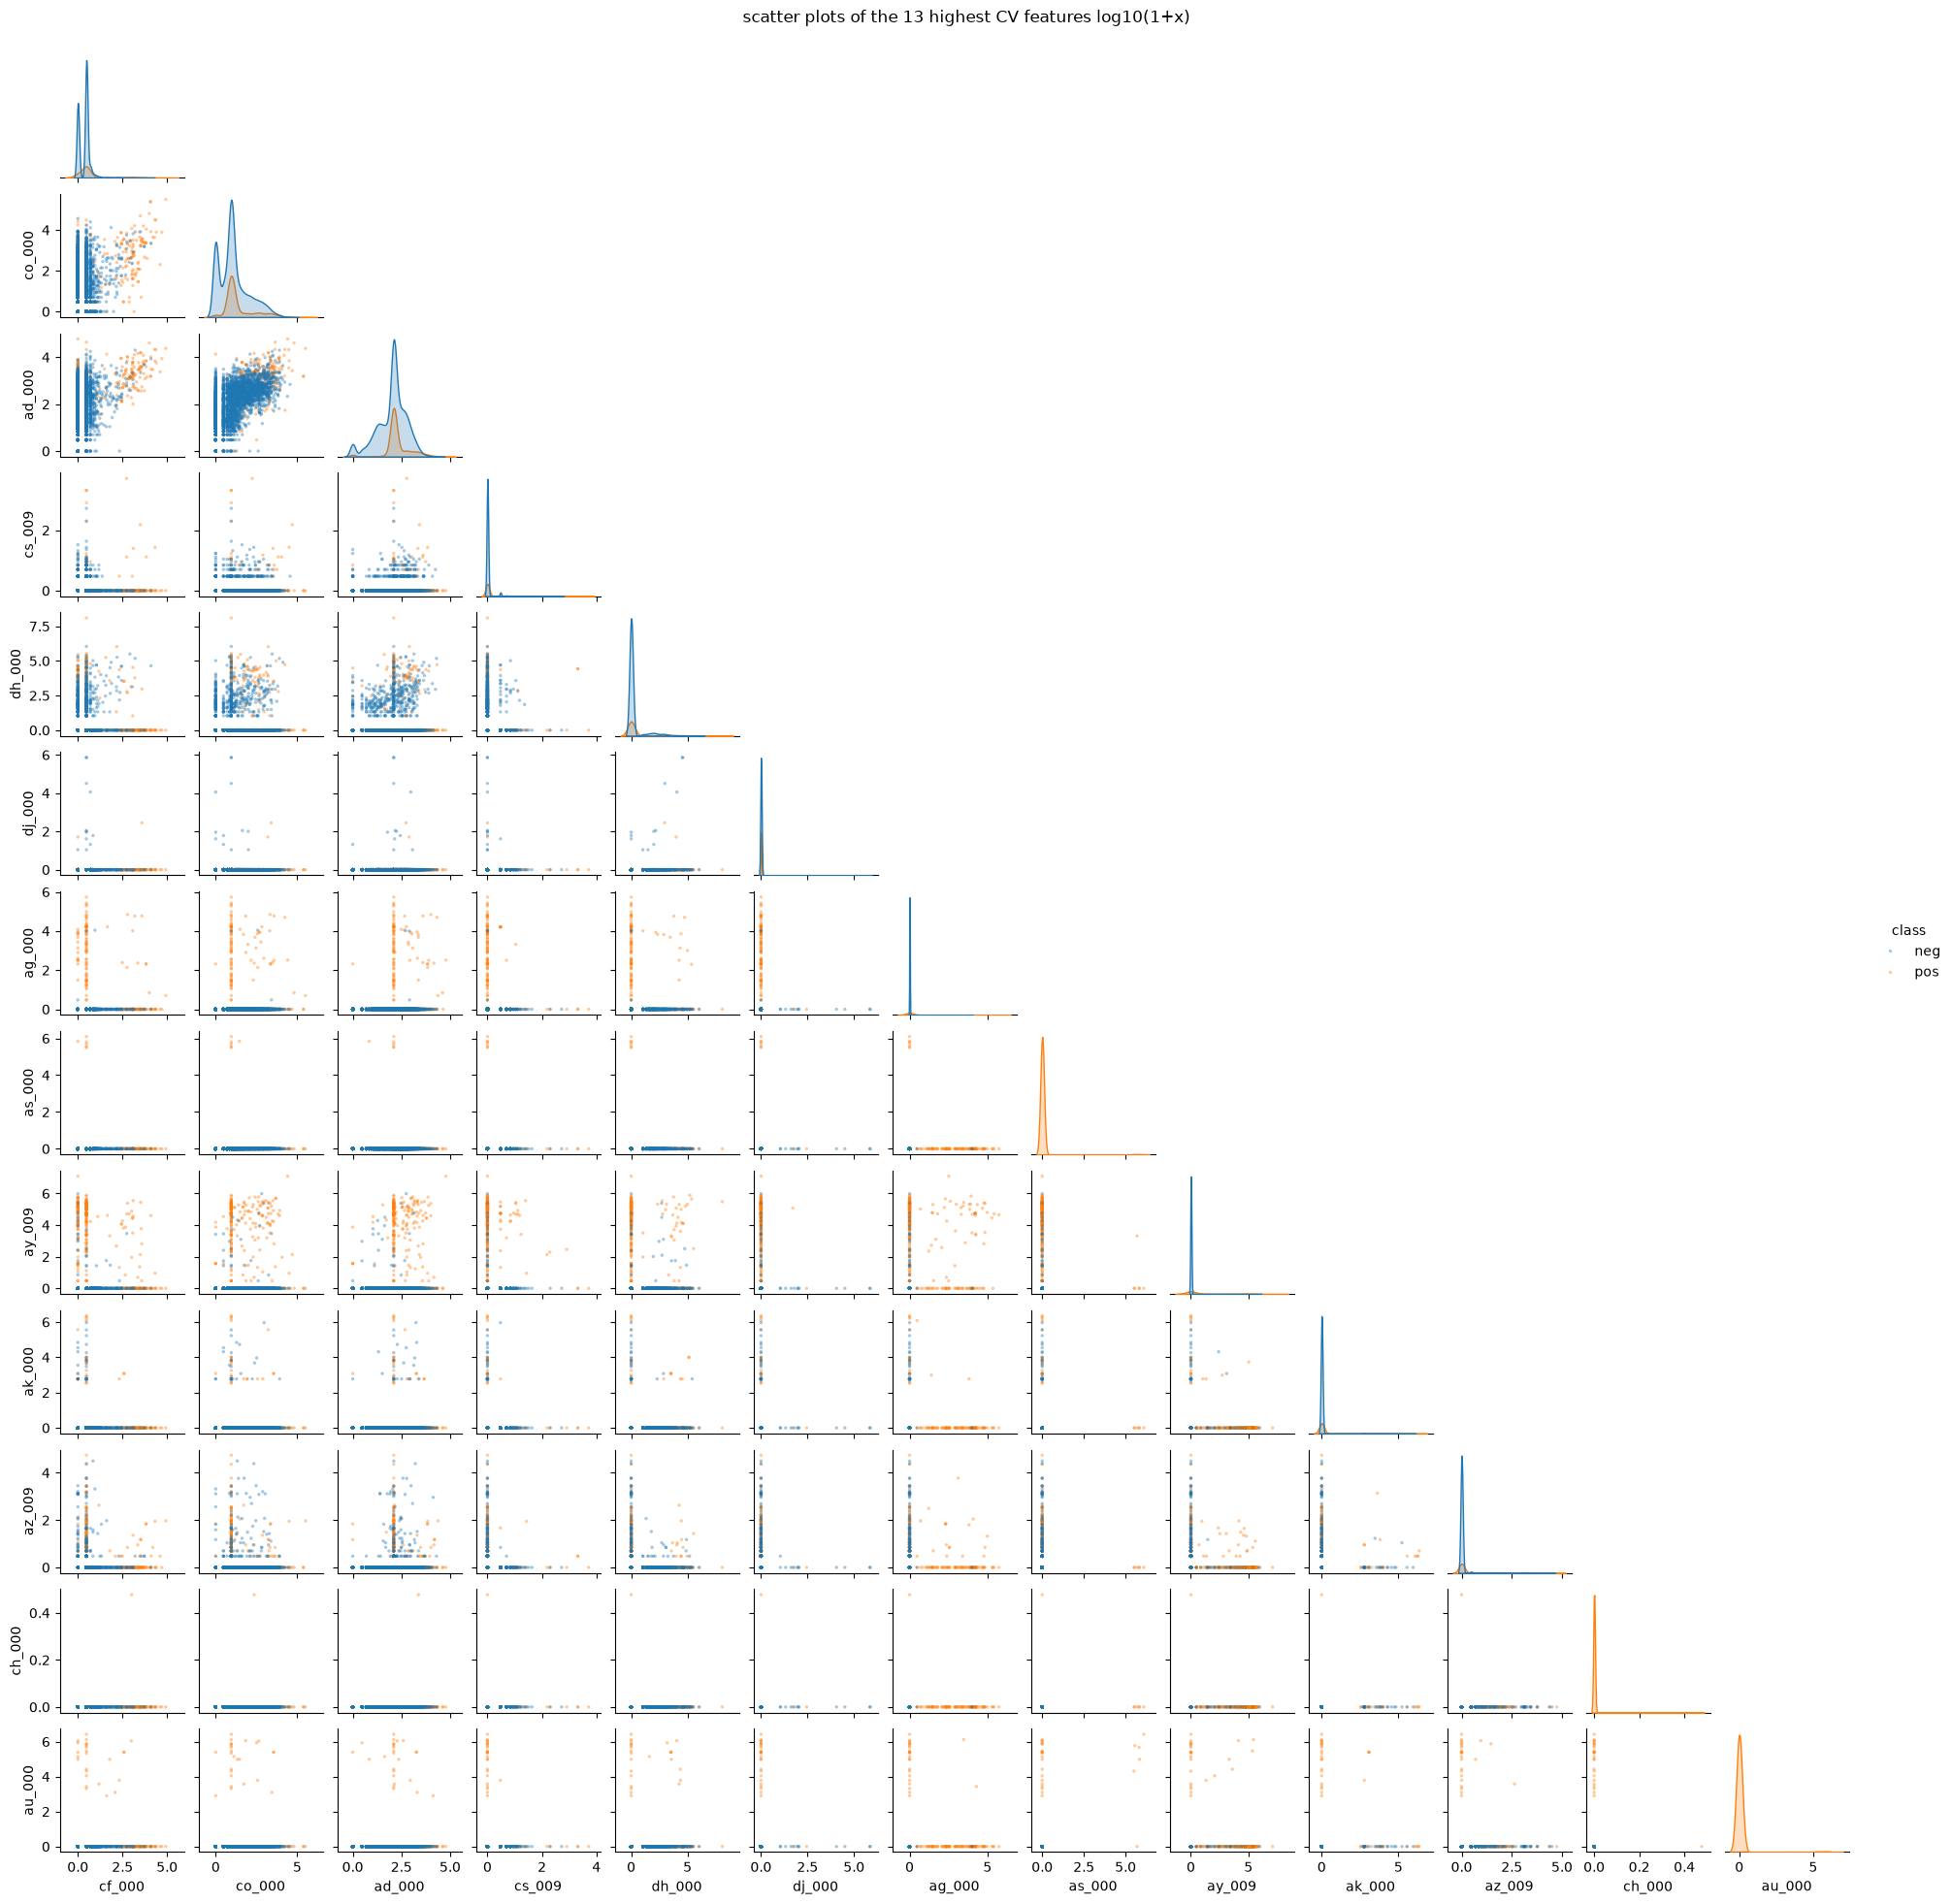

In [12]:
#scatter plot with all 60000 rows was very slow so i am taking all the positives and 4000 random negatves
#values are very skewd so log10(1+x) is only used for plotting 
rng = np.random.default_rng(SEED)
posidx = np.where(y_train == 1)[0]
negidx = rng.choice(np.where(y_train == 0)[0], 4000, replace=False)
idx = np.concatenate([posidx, negidx])
viz = np.log10(1 + X_train.iloc[idx][topcv].clip(lower=0))
viz["class"] = np.where(y_train[idx] == 1, "pos", "neg")
g = sns.pairplot(viz, hue="class", hue_order=["neg", "pos"], plot_kws=dict(s=6, alpha=0.4, linewidth=0), diag_kind="kde", corner=True, height=1.5)
g.figure.suptitle("scatter plots of the 13 highest CV features log10(1+x)", y=1.01)
plt.show()

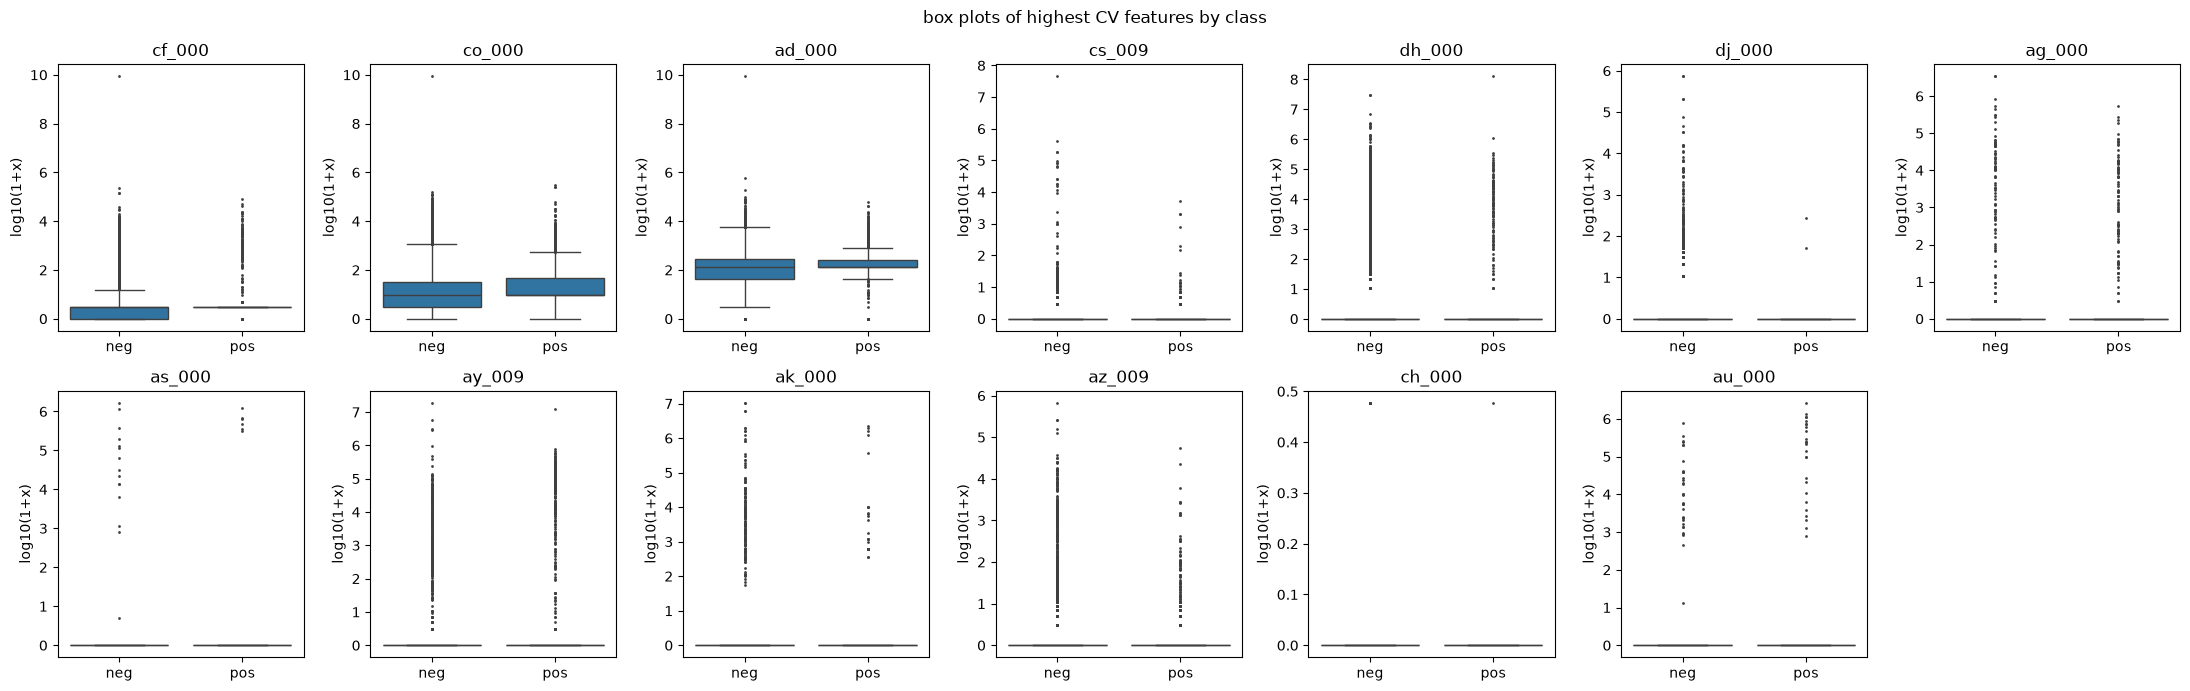

In [13]:
#drawing one box plot per feature split by class, box ranges from Q1 to Q3 ,line inside is the median and any point outside the whisker is outlier
full = np.log10(1 + X_train[topcv].clip(lower=0))
full["class"] = np.where(y_train == 1, "pos", "neg")
fig, axes = plt.subplots(2, 7, figsize=(22, 7))
axes = axes.ravel()
for i in range(len(topcv)):
    f = topcv[i]
    sns.boxplot(data=full, x="class", y=f, order=["neg", "pos"], ax=axes[i], fliersize=1)
    axes[i].set_title(f)
    axes[i].set_xlabel("")
    axes[i].set_ylabel("log10(1+x)")
axes[13].axis("off") #there are only 13 so the 14th box is empty 
plt.suptitle("box plots of highest CV features by class")
plt.tight_layout()
plt.show()

In [14]:
#median of each of these feature for neg and pos
mediantable = X_train[topcv].groupby(y_train).median().T
mediantable.columns = ["neg median", "pos median"]
mediantable

,neg median,pos median
cf_000,2.0,2.0
co_000,8.0,8.0
ad_000,126.0,126.0
cs_009,0.0,0.0
dh_000,0.0,0.0
dj_000,0.0,0.0
ag_000,0.0,0.0
as_000,0.0,0.0
ay_009,0.0,0.0
ak_000,0.0,0.0


b v

In [15]:
#counting positive and negatives in train and test
print("train neg:", (y_train==0).sum(), " pos:", (y_train==1).sum())
print("test neg:", (y_test==0).sum(), " pos:", (y_test==1).sum())
print("pos fraction train:", round(y_train.mean(), 4), " test:", round(y_test.mean(), 4))

train neg: 59000  pos: 1000
test neg: 15625  pos: 375
pos fraction train: 0.0167  test: 0.0234


In [16]:
#writing one function so i dont have to repeat confusion matrix ,roc ,auc and error for evry model again and again
#cost is from the scania description , false positive = 10 and false negative = 500 (missing a failed truck is much worse)
results = {}

def evaluate(name, model, X_tr, y_tr, X_te, y_te):
    out = {}
    fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))
    splits = [("train", X_tr, y_tr, axes[1]), ("test", X_te, y_te, axes[2])]
    for split, X, y, ax in splits:
        prob = model.predict_proba(X)[:, 1]
        pred = (prob >= 0.5).astype(int)
        cm = confusion_matrix(y, pred, labels=[0, 1])
        tn, fp, fn, tp = cm.ravel()
        auc = roc_auc_score(y, prob)
        err = 1 - accuracy_score(y, pred)
        out[split] = {"AUC": auc, "misclassification": err, "TN": tn, "FP": fp, "FN": fn, "TP": tp,
                      "TPR": tp/(tp+fn), "FPR": fp/(fp+tn), "cost": 10*fp + 500*fn}
        fpr, tpr, _ = roc_curve(y, prob)
        axes[0].plot(fpr, tpr, label=split + " AUC = " + str(round(auc, 4)))
        ConfusionMatrixDisplay(cm, display_labels=["neg", "pos"]).plot(ax=ax, colorbar=False, values_format="d")
        ax.set_title(split + " confusion matrix, error = " + str(round(err*100, 3)) + "%")
    axes[0].plot([0, 1], [0, 1], "k--")  # random guess line , diagonal
    axes[0].set_xlabel("False positive rate")
    axes[0].set_ylabel("True positive rate")
    axes[0].set_title("ROC " + name)
    axes[0].legend(loc="lower right")
    plt.tight_layout()
    plt.show()
    df = pd.DataFrame(out).T
    results[name] = df
    print(df)
    return df

c

time taken: 61 sec


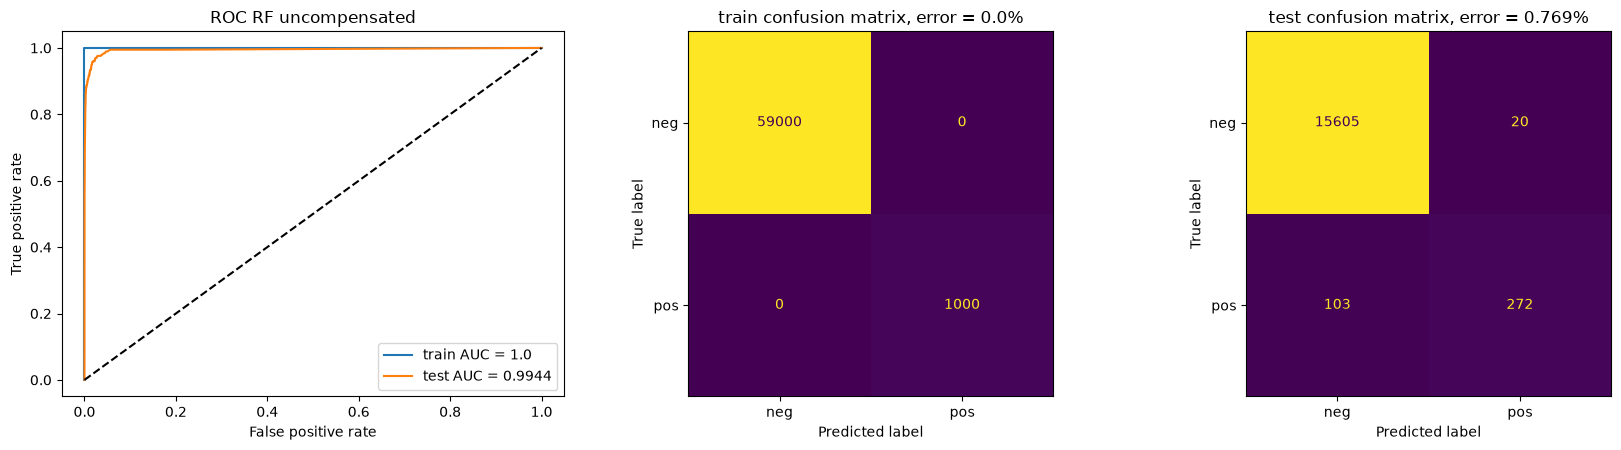

            AUC  misclassification       TN    FP     FN      TP       TPR  \
train  1.000000           0.000000  59000.0   0.0    0.0  1000.0  1.000000   
test   0.994351           0.007687  15605.0  20.0  103.0   272.0  0.725333   

           FPR     cost  
train  0.00000      0.0  
test   0.00128  51700.0  
OOB error: 0.0058
Test error: 0.00769


In [17]:
#random forest without doing anything for class imbalnce , 500 trees
#oob_score = True gives us the out of bag error directly no need of CV
start = time.time()
rf = RandomForestClassifier(n_estimators=500, max_features="sqrt", oob_score=True, n_jobs=-1, random_state=SEED)
rf.fit(X_train, y_train)
print("time taken:", round(time.time()-start), "sec")
rfres = evaluate("RF uncompensated", rf, X_train, y_train, X_test, y_test)
print("OOB error:", round(1 - rf.oob_score_, 5))
print("Test error:", round(rfres.loc["test", "misclassification"], 5))

d

time taken: 43 sec


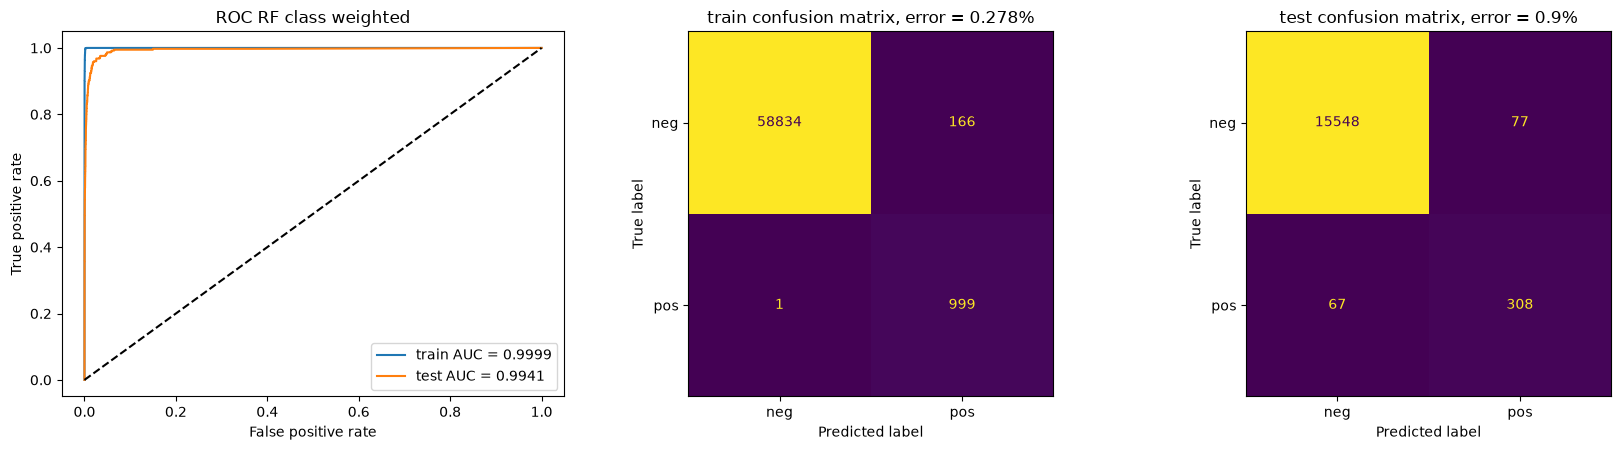

            AUC  misclassification       TN     FP    FN     TP       TPR  \
train  0.999910           0.002783  58834.0  166.0   1.0  999.0  0.999000   
test   0.994112           0.009000  15548.0   77.0  67.0  308.0  0.821333   

            FPR     cost  
train  0.002814   2160.0  
test   0.004928  34270.0  
OOB error: 0.00833
Test error: 0.009


In [18]:
#first way , class_weight gives more weightage to pos in every bootstrap sample
#min_samples_leaf = 5 so that the trees dont overfit on the few pos points
start=time.time()
rfw = RandomForestClassifier(n_estimators=500, max_features="sqrt", class_weight="balanced_subsample",
                             min_samples_leaf=5, oob_score=True, n_jobs=-1, random_state=SEED)
rfw.fit(X_train, y_train)
print("time taken:", round(time.time()-start), "sec")
rfwres = evaluate("RF class weighted", rfw, X_train, y_train, X_test, y_test)
print("OOB error:", round(1 - rfw.oob_score_, 5))
print("Test error:", round(rfwres.loc["test", "misclassification"], 5))

time taken: 13 sec


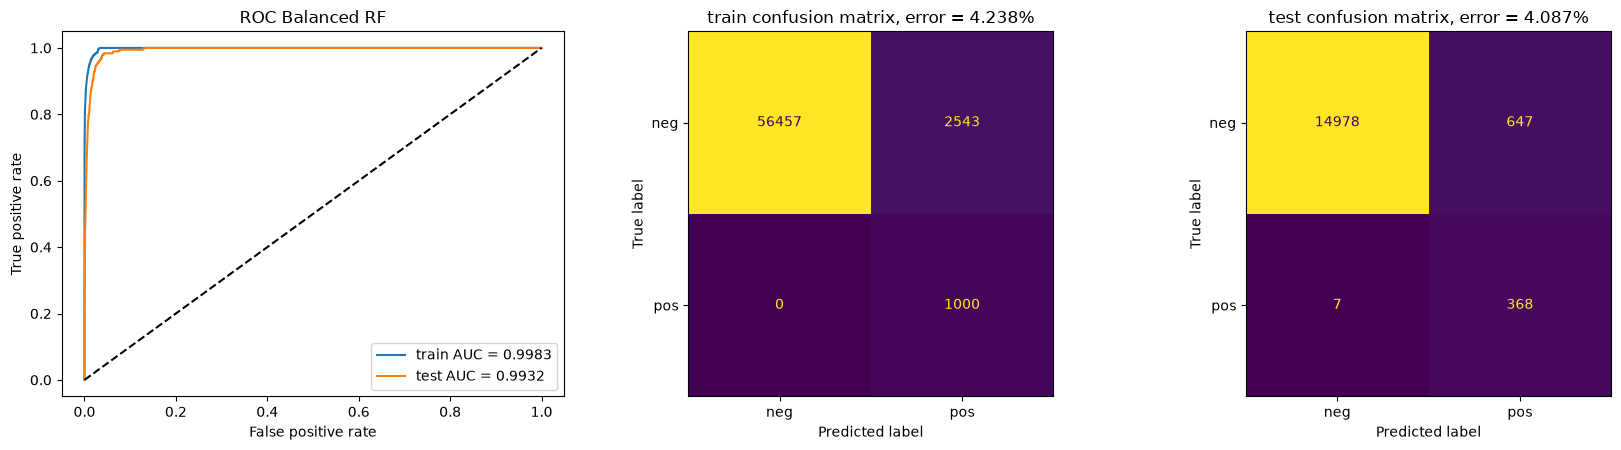

            AUC  misclassification       TN      FP   FN      TP       TPR  \
train  0.998308           0.042383  56457.0  2543.0  0.0  1000.0  1.000000   
test   0.993209           0.040875  14978.0   647.0  7.0   368.0  0.981333   

            FPR     cost  
train  0.043102  25430.0  
test   0.041408   9970.0  


In [19]:
#second way , balanced random forest undersamples neg class for every tree so each tree sees balanced data
start = time.time()
brf = BalancedRandomForestClassifier(n_estimators=500, max_features="sqrt", sampling_strategy="all",
                                     replacement=True, bootstrap=False, n_jobs=-1, random_state=SEED)
brf.fit(X_train, y_train)
print("time taken:", round(time.time()-start), "sec")
brfres = evaluate("Balanced RF", brf, X_train, y_train, X_test, y_test)

In [20]:
#comparing all 3 random forests on test set side by side
comparison = pd.DataFrame({k: results[k].loc["test"] for k in ["RF uncompensated", "RF class weighted", "Balanced RF"]}).T
comparison[["AUC", "misclassification", "TP", "FN", "FP", "TPR", "FPR", "cost"]]

,AUC,misclassification,TP,FN,FP,TPR,FPR,cost
RF uncompensated,0.994351,0.007687,272.0,103.0,20.0,0.725333,0.001280,51700.0
RF class weighted,0.994112,0.009000,308.0,67.0,77.0,0.821333,0.004928,34270.0
Balanced RF,0.993209,0.040875,368.0,7.0,647.0,0.981333,0.041408,9970.0


e

In [21]:
#XGBoost with logistic loss , reg_alpha is the L1 penalty so we will tune it using 5 fold CV
#n_jobs=-1 inside xgboost and n_jobs=1 in gridsearch because otherwise it kept crashing on windows (BrokenProcessPool error)
xgbparams = dict(objective="binary:logistic", n_estimators=300, learning_rate=0.1, max_depth=6,
                 subsample=0.9, colsample_bytree=0.8, tree_method="hist", eval_metric="logloss",
                 random_state=SEED, n_jobs=-1,)
alphas = [0, 0.01, 0.1, 1, 10, 100, 1000,]
cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

start = time.time()
gsxgb = GridSearchCV(XGBClassifier(**xgbparams), {"reg_alpha": alphas}, cv=cv5,
                     scoring={"accuracy": "accuracy", "roc_auc": "roc_auc"}, refit="accuracy", n_jobs=1)
gsxgb.fit(X_train, y_train)
print("time taken:", round(time.time()-start), "sec")

cvxgb = pd.DataFrame({"alpha": alphas,
                      "CV error": 1 - gsxgb.cv_results_["mean_test_accuracy"],
                      "CV error std": gsxgb.cv_results_["std_test_accuracy"],
                      "CV AUC": gsxgb.cv_results_["mean_test_roc_auc"]})
print(cvxgb)
bestalpha = gsxgb.best_params_["reg_alpha"]
print("best alpha:", bestalpha)

time taken: 1467 sec
     alpha  CV error  CV error std    CV AUC
0     0.00  0.005767  3.887301e-04  0.988527
1     0.01  0.005767  3.472111e-04  0.987708
2     0.10  0.005783  3.822448e-04  0.988822
3     1.00  0.005867  4.102845e-04  0.988587
4    10.00  0.006517  6.377042e-04  0.989288
5   100.00  0.011433  3.993050e-04  0.982663
6  1000.00  0.016667  1.110223e-16  0.500000
best alpha: 0


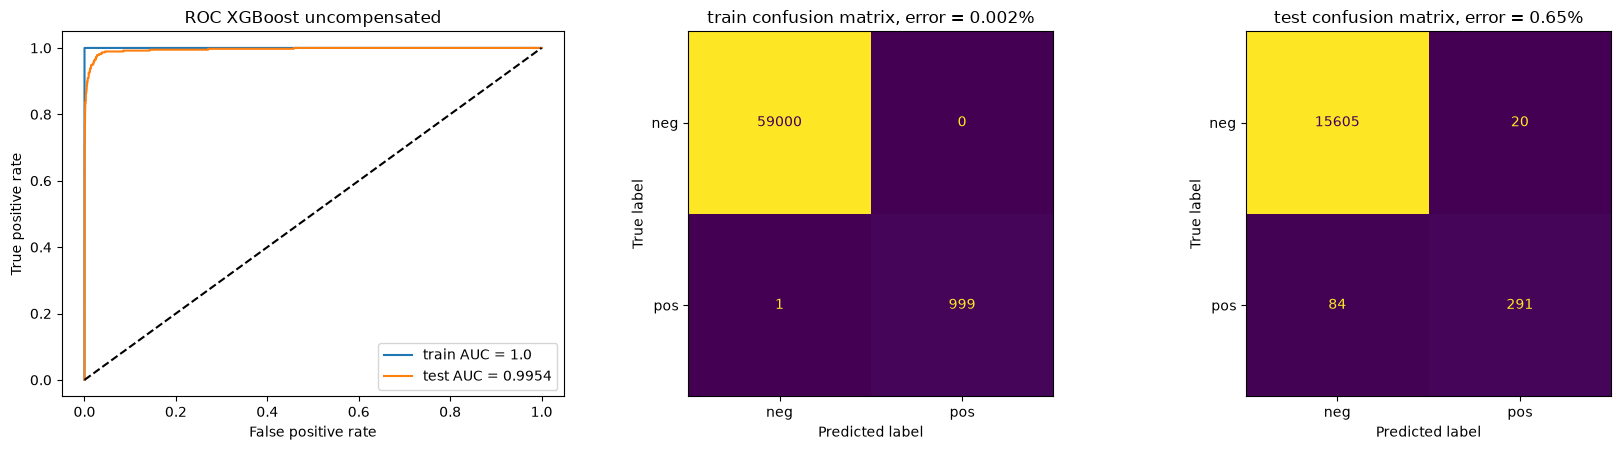

           AUC  misclassification       TN    FP    FN     TP    TPR      FPR  \
train  1.00000           0.000017  59000.0   0.0   1.0  999.0  0.999  0.00000   
test   0.99539           0.006500  15605.0  20.0  84.0  291.0  0.776  0.00128   

          cost  
train    500.0  
test   42200.0  
5 fold CV error: 0.00577
Test error: 0.0065


In [22]:
#best_estimator_ is already refitted on the full training data with best alpha
xgb = gsxgb.best_estimator_
xgbres = evaluate("XGBoost uncompensated", xgb, X_train, y_train, X_test, y_test)
cverrxgb = 1 - gsxgb.best_score_
print("5 fold CV error:", round(cverrxgb, 5))
print("Test error:", round(xgbres.loc["test", "misclassification"], 5))

f

In [23]:
#SMOTE has to be done inside every fold , if we do it before CV the synthetic points leak into the validation fold
#imblearn pipeline does that automaticaly , smote only runs on the training part of every fold
pipe = ImbPipeline([("smote", SMOTE(k_neighbors=5, random_state=SEED)),
                    ("xgb", XGBClassifier(**xgbparams))])
start = time.time()
gssmote = GridSearchCV(pipe, {"xgb__reg_alpha": alphas}, cv=cv5,
                       scoring={"accuracy": "accuracy", "roc_auc": "roc_auc"}, refit="accuracy", n_jobs=1)
gssmote.fit(X_train, y_train)
print("time taken:", round(time.time()-start), "sec")   #this one takes the longest ~25 min

cvsmote = pd.DataFrame({"alpha": alphas,
                        "CV error": 1 - gssmote.cv_results_["mean_test_accuracy"],
                        "CV error std": gssmote.cv_results_["std_test_accuracy"],
                        "CV AUC": gssmote.cv_results_["mean_test_roc_auc"]})
print(cvsmote)
bestalphasmote = gssmote.best_params_["xgb__reg_alpha"]
print("best alpha:", bestalphasmote)

time taken: 1135 sec
     alpha  CV error  CV error std    CV AUC
0     0.00  0.006550      0.000490  0.988679
1     0.01  0.006533      0.000763  0.988399
2     0.10  0.006600      0.000501  0.988079
3     1.00  0.006517      0.000731  0.988754
4    10.00  0.007667      0.000553  0.987516
5   100.00  0.017283      0.001366  0.984635
6  1000.00  0.040417      0.001104  0.981359
best alpha: 1


after SMOTE: (118000, 170)  class counts: [59000 59000]


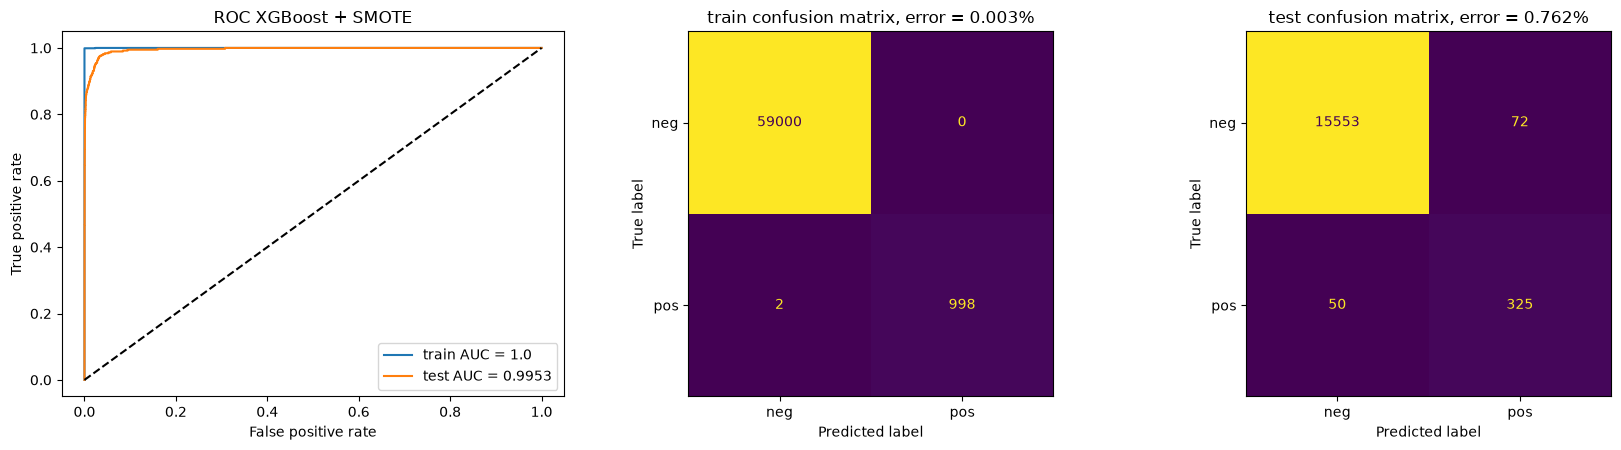

            AUC  misclassification       TN    FP    FN     TP       TPR  \
train  0.999976           0.000033  59000.0   0.0   2.0  998.0  0.998000   
test   0.995340           0.007625  15553.0  72.0  50.0  325.0  0.866667   

            FPR     cost  
train  0.000000   1000.0  
test   0.004608  25720.0  
5 fold CV error (smote inside folds): 0.00652
Test error: 0.00762


In [24]:
#final model , smote on full training set and then xgboost with best alpha
X_sm, y_sm = SMOTE(k_neighbors=5, random_state=SEED).fit_resample(X_train, y_train)
print("after SMOTE:", X_sm.shape, " class counts:", np.bincount(y_sm))
xgbs = XGBClassifier(**xgbparams, reg_alpha=bestalphasmote)
xgbs.fit(X_sm, y_sm)


#train metrics are on original training data not the smote one , only real trucks
xgbsres = evaluate("XGBoost + SMOTE", xgbs, X_train, y_train, X_test, y_test)
cverrsmote = 1 - gssmote.best_score_
print("5 fold CV error (smote inside folds):", round(cverrsmote, 5))
print("Test error:", round(xgbsres.loc["test", "misclassification"], 5))

In [25]:
#just to show the wrong way , smote first and then CV on the balanced synthetic data
wrong = cross_val_score(XGBClassifier(**xgbparams, reg_alpha=bestalphasmote), X_sm, y_sm, cv=cv5, scoring="accuracy", n_jobs=1)
psm = xgbs.predict_proba(X_sm)[:, 1]
print("wrong way CV error :", round(1 - wrong.mean(), 5))
print("right way CV error :", round(cverrsmote, 5))
print("training error on smote data:", round(1 - accuracy_score(y_sm, psm >= 0.5), 5), " AUC:", round(roc_auc_score(y_sm, psm), 4))

wrong way CV error : 0.0023
right way CV error : 0.00652
training error on smote data: 2e-05  AUC: 1.0


In [26]:
#final table with all the models side by side
summary = pd.DataFrame({k: v.loc["test"] for k, v in results.items()}).T
summary["train AUC"] = [v.loc["train", "AUC"] for v in results.values()]
summary["train error"] = [v.loc["train", "misclassification"] for v in results.values()]
summary = summary[["train AUC", "train error", "AUC", "misclassification", "TP", "FN", "FP", "TPR", "FPR", "cost"]]
summary.columns = ["train AUC", "train error", "test AUC", "test error", "TP", "FN", "FP", "test TPR", "test FPR", "test cost"]
summary

,train AUC,train error,test AUC,test error,TP,FN,FP,test TPR,test FPR,test cost
RF uncompensated,1.000000,0.000000,0.994351,0.007687,272.0,103.0,20.0,0.725333,0.001280,51700.0
RF class weighted,0.999910,0.002783,0.994112,0.009000,308.0,67.0,77.0,0.821333,0.004928,34270.0
Balanced RF,0.998308,0.042383,0.993209,0.040875,368.0,7.0,647.0,0.981333,0.041408,9970.0
XGBoost uncompensated,1.000000,0.000017,0.995390,0.006500,291.0,84.0,20.0,0.776000,0.001280,42200.0
XGBoost + SMOTE,0.999976,0.000033,0.995340,0.007625,325.0,50.0,72.0,0.866667,0.004608,25720.0


Now answering all the questions that were theoritical for question 1

b i
For the missing values i used median imputation , mean gets pulled a lot by the huge vaules in these features (they are counters and histogram bins so very skewed) so median is safer
Other techniques are mean , mode , KNN imputer or iterative imputer (MICE) but those are very slow for 60000 rows x 170 coloumns 
99% of rows have atleast one missing value so droping rows is not an option at all , we would loose almost all data
br_000, bq_000 , bp_000 are missing in ~80% of rows
train is imputed with train medians and test with test medians

b ii
CV table is above sorted from high to low, cf_000, co_000 and ad_000 have the highest CV ~245
cd_000 is constant (std = 0) so it doesnt give any information , i left it out of the correlation matrix

b iii
130 pairs out of 14196 have |r| > 0.9 , so there are groups of features that are basicaly measuring the same thing
it makes sense becuase alot of them are histogram bins of the same counter (like ag_000 to ag_009)
most of the heatmap is still close to 0

b iv
13 features = cf_000, co_000, ad_000, cs_009, dh_000, dj_000, ag_000, as_000, ay_009, ak_000, az_009, ch_000, au_000
the median is exactly same for neg and pos for all 13 , and for most of them its 0
so from the plots i cant really say these are significant , high CV only means lot of variation it doesnt mean thta the feature seperates the classes
the scatter plots overlap a lot between pos and neg

b v
train = 59000 neg , 1000 pos
test = 15625 neg , 375 pos
only 1.7% of train is positive so yes the data is very imbalanced , a model that just predicts neg everytime gets 98.3% accuracy , therefore accuracy alone is misleading here

c
OOB error = 0.580% and test error = 0.769% , OOB is a little optimistic but quiet close
train error is ~0 beacuse forest basically memorizes the training data , thats why OOB is used
test AUC = 0.9944 , but 103 out of 375 failed trucks were missed (FN) which is the expensive mistake , cost = 51,700

d
tried two ways
class_weight = balanced_subsample , FN went from 103 to 67 but FP went from 20 to 77, test error = 0.900% OOB error = 0.833% , cost = 34,270
Balanced RF (undersampling for every tree) , FN only 7 but FP = 647 , test error = 4.088% , cost = 9,970
so compensating increases the error but catches much more failures , with the scania cost balanced RF is the best of the three
AUC is almost same for all three ~0.993-0.994 , which indirectly suggests compensation mostly moves the decision threshold it doesnt rank better

e
alpha was tuned from 0 to 1000 using 5 fold CV, best alpha = 0 , larger alpha only made it worse ie penalty did not help
5 fold CV error = 0.577% and test error = 0.650% , CV is little optimistic but close
test AUC = 0.9954 best so far , FN = 84 , FP = 20 , cost = 42,200
lowest test error of all models

f
SMOTE was applied inside each fold with the imblearn pipeline , best alpha = 1
right way CV error = 0.652% , test error = 0.763%
wrong way CV (smote before CV) = 0.230% which is way too optimistic becuase the validation folds have synthetic points made from the training points , it leaks
compared to e , FN dropped from 84 to 50 and FP went from 20 to 72 , test error slightly up but cost went down from 42,200 to 25,720
AUC almost same (0.9953) so again smote mostly helps the minority class at the threshold
if we only care about error uncompensated xgboost is better , if we care about not missing failed trucks the smote one is better


2. ISLR 6.6.3
(a) iv , training RSS steadily decreases. as s increases the constraint becomes loose so model gets more flexibile and fits training data better , at large s its just least squares
(b) ii , test RSS decreases first and then increases in a U shape. starts at the null model , gets better as useful predictors come in , then starts overfitting
(c) iii , variance steadily increases. at s = 0 all betas are 0 so variance is 0 , more flexibility = more variance
(d) iv , squared bias steadily decreases , model becomes more flexible
(e) v , irreducible error remains constant , it doesnt depend on model at all


3. ISLR 6.6.5
n = p = 2 , x11 = x12 = a , x21 = x22 = b , and y1 + y2 = 0 , x11 + x21 = 0 , x12 + x22 = 0 so intercept is 0

(a) ridge optimization problem
minimize (y1 - b1 x11 - b2 x12)^2 + (y2 - b1 x21 - b2 x22)^2 + lambda (b1^2 + b2^2)

(b)
since x11 = x12 and x21 = x22 the RSS part only depends on (b1 + b2)
so for any fixed sum b1 + b2 = c , the penalty b1^2 + b2^2 is smallest when b1 = b2 = c/2
taking derivative wrt b1 and b2 and setting it equal to 0 , both equations are same except the lambda b1 term and lambda b2 term
subtracting them gives 2 lambda (b1 - b2) = 0 so b1 = b2 (lambda > 0)

(c) lasso optimization problem
minimize (y1 - b1 x11 - b2 x12)^2 + (y2 - b1 x21 - b2 x22)^2 + lambda (|b1| + |b2|)

(d)
again RSS only depends on b1 + b2
penalty |b1| + |b2| is same for every b1 , b2 with same sign and same sum , like b1 + b2 = c with b1 , b2 >= 0 gives |b1| + |b2| = c always
so every point on that line segment gives the same objective , the solution is not unique
geometricaly the RSS contours are paralel to the edge of the diamond |b1| + |b2| = s so they touch the whole edge not just a corner
all solutions are b1 + b2 = c with b1 , b2 >= 0 (or both <= 0 if c is negative)


4. ISLR 8.4.5

In [27]:
#10 bootstrap estimates of P(Red|X)
p = np.array([0.1, 0.15, 0.2, 0.2, 0.55, 0.6, 0.6, 0.65, 0.7, 0.75])
votesred = (p > 0.5).sum()
print("majority vote:", votesred, "out of 10 say Red")
print("average probability:", p.mean())

majority vote: 6 out of 10 say Red
average probability: 0.45


majority vote = 6 out of 10 are above 0.5 so the final answer is Red
average probability = 0.45 which is < 0.5 so the final answer is Green
both approches give a different classification here


5. ISLR 9.7.3

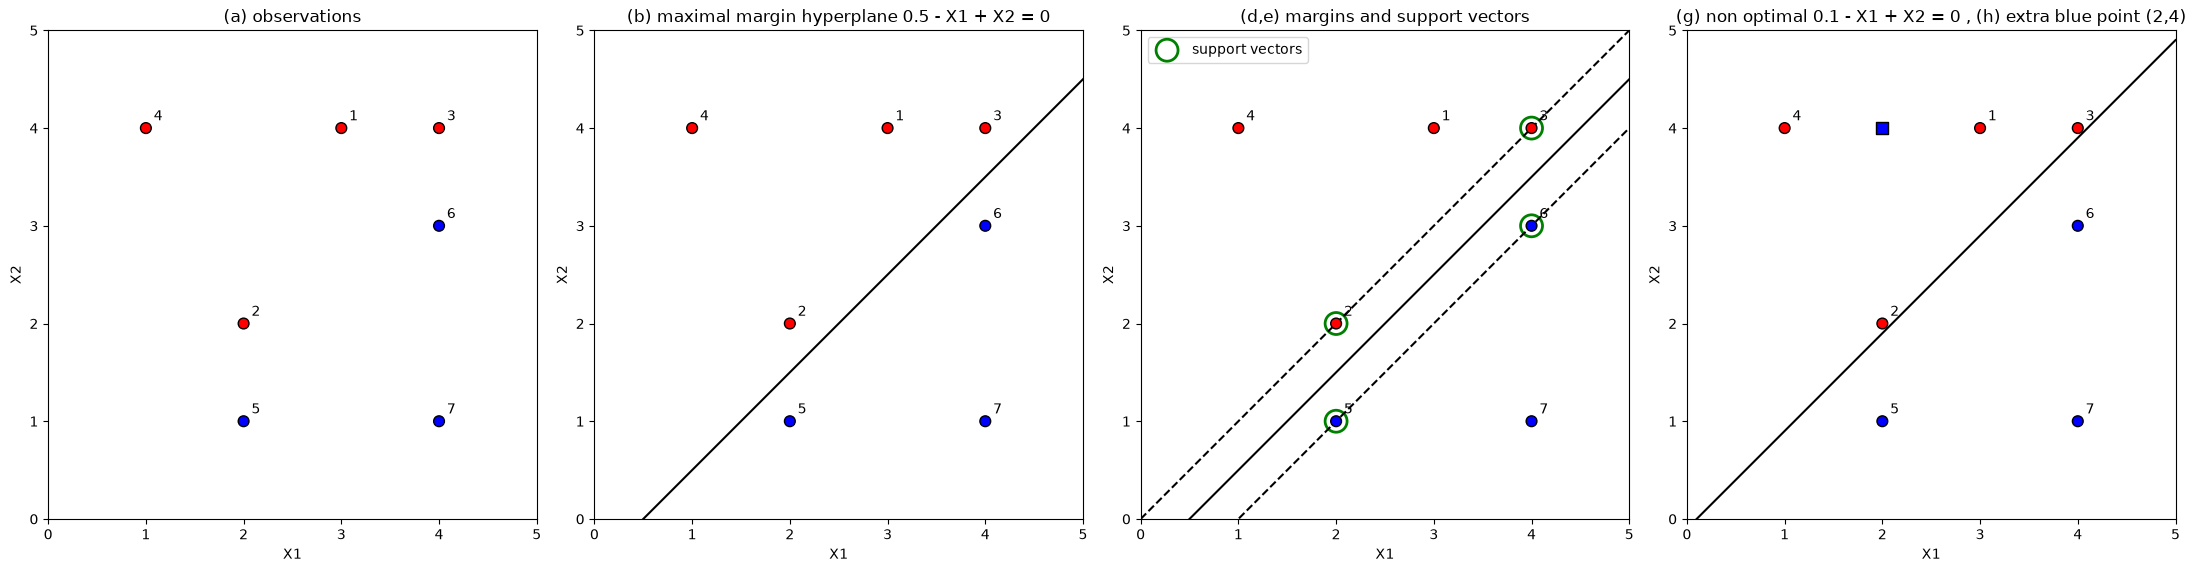

In [28]:
#7 observations , first 4 are red and last 3 are blue
X93 = np.array([[3, 4], [2, 2], [4, 4], [1, 4], [2, 1], [4, 3], [4, 1]])
y93 = np.array(["red", "red", "red", "red", "blue", "blue", "blue"])
xs = np.linspace(0, 5, 100)

#same base plot for every part so writing a function for it
def base(ax, title):
    ax.scatter(X93[:, 0], X93[:, 1], c=y93, s=60, edgecolor="k", zorder=3)
    for i in range(len(X93)):
        ax.annotate(str(i+1), (X93[i, 0] + 0.08, X93[i, 1] + 0.08))   # obs number
    ax.set_xlim(0, 5)
    ax.set_ylim(0, 5)
    ax.set_xlabel("X1")
    ax.set_ylabel("X2")
    ax.set_title(title)
    ax.set_aspect("equal")

fig, axes = plt.subplots(1, 4, figsize=(22, 5.5))
base(axes[0], "(a) observations")

base(axes[1], "(b) maximal margin hyperplane 0.5 - X1 + X2 = 0")
axes[1].plot(xs, xs - 0.5, "k-")

base(axes[2], "(d,e) margins and support vectors")
axes[2].plot(xs, xs - 0.5, "k-")
axes[2].plot(xs, xs, "k--")
axes[2].plot(xs, xs - 1, "k--")
sv = X93[[1, 2, 4, 5]]
axes[2].scatter(sv[:, 0], sv[:, 1], s=250, facecolor="none", edgecolor="green", lw=2, label="support vectors")
axes[2].legend(loc="upper left")

base(axes[3], "(g) non optimal 0.1 - X1 + X2 = 0 , (h) extra blue point (2,4)")
axes[3].plot(xs, xs - 0.1, "k-")
axes[3].scatter([2], [4], c="blue", marker="s", s=80, edgecolor="k")
plt.tight_layout()
plt.show()

In [29]:
#cross checking with sklearn , very large C means its basically hard margin
from sklearn.svm import SVC
svm = SVC(kernel="linear", C=1e6)
svm.fit(X93, (y93 == "red").astype(int))
w = svm.coef_[0]
b0 = svm.intercept_[0]
#dividing by beta2 so it matches the form 0.5 - X1 + X2
print("beta0, beta1, beta2 :", np.round(np.array([b0, w[0], w[1]]) / w[1], 3))
print("support vectors (obs number):", svm.support_ + 1)
print("margin:", round(1 / np.linalg.norm(w), 4))


beta0, beta1, beta2 : [ 0.5 -1.   1. ]
support vectors (obs number): [5 6 2 3]
margin: 0.3537


(a) plotted above , red = obs 1-4 and blue = obs 5-7

(b) the maximal margin hyperplane goes in the middle of the pairs (2,2),(2,1) and (4,4),(4,3)
so it passes through (2,1.5) and (4,3.5) , slope = 1
X2 = X1 - 0.5 which is 0.5 - X1 + X2 = 0

(c) classify to Red if 0.5 - X1 + X2 > 0 and to Blue otherwise
beta0 = 0.5 , beta1 = -1 , beta2 = 1

(d) the margin lines are X2 = X1 and X2 = X1 - 1 (dashed lines)
margin = distance from hyperplane to each line = 0.5/sqrt(2) ~= 0.354 , same as sklearn gave

(e) support vectors are (2,2) , (4,4) , (2,1) , (4,3) ie obs 2,3,5,6

(f) obs 7 is (4,1) and its far away from the margin , its not a support vector
so moving it a little bit wont change the maximal margin hyperplane , only support vectors affect it

(g) 0.1 - X1 + X2 = 0 , it still seperates the two classes but its very close to the blue points (2,1) and (4,3) so its not the maximal one

(h) adding a blue point at (2,4) , its on the red side of the hyperplane and above red point (2,2)
so now the two classes cant be seperated by any straight line (hyperplane)


6. Extra practice (not graded)

5.4.2 h simulated probability: 0.63


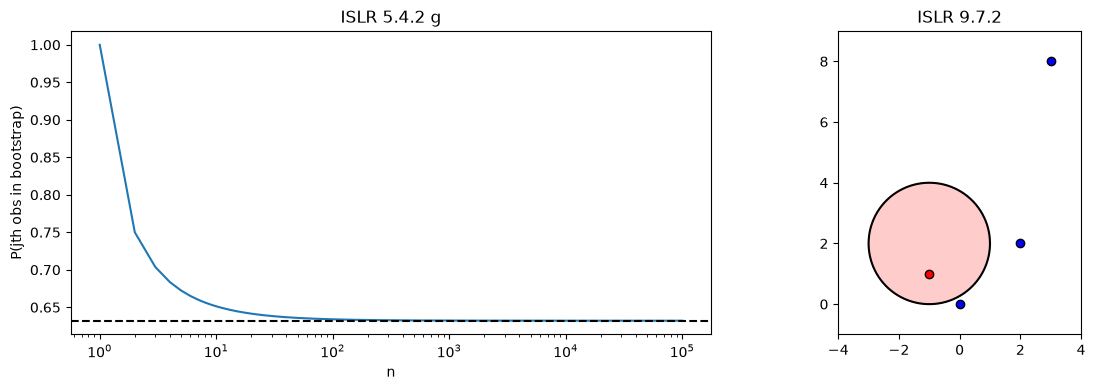

In [30]:
#ISLR 5.4.2 g , probability that jth obs is in the bootstrap sample = 1-(1-1/n)^n
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
n = np.arange(1, 100001)
axes[0].semilogx(n, 1 - (1 - 1/n)**n)
axes[0].axhline(1 - np.exp(-1), ls="--", c="k")   # goes to 1 - 1/e ~= 0.632
axes[0].set_xlabel("n")
axes[0].set_ylabel("P(jth obs in bootstrap)")
axes[0].set_title("ISLR 5.4.2 g")

#5.4.2 h , simulating it
store = []
for i in range(10000):
    sample = np.random.default_rng(i).integers(1, 101, 100)
    store.append((sample == 4).any())
print("5.4.2 h simulated probability:", np.mean(store))

#ISLR 9.7.2 circle (1+X1)^2 + (2-X2)^2 = 4 , red inside blue outside
t = np.linspace(0, 2*np.pi, 200)
axes[1].plot(-1 + 2*np.cos(t), 2 + 2*np.sin(t), "k")
axes[1].fill(-1 + 2*np.cos(t), 2 + 2*np.sin(t), color="red", alpha=0.2)
points = [((0, 0), "blue"), ((-1, 1), "red"), ((2, 2), "blue"), ((3, 8), "blue")]
for pt, c in points:
    axes[1].scatter(pt[0], pt[1], c=c, edgecolor="k")
axes[1].set_xlim(-4, 4)
axes[1].set_ylim(-1, 9)
axes[1].set_title("ISLR 9.7.2")
axes[1].set_aspect("equal")
plt.tight_layout()
plt.show()